# 03. YOLO26s: только реальные микрофотографии

Датасет — `data_real`, класс — `particle`. Пять независимых запусков из исходных весов YOLO26s.
Выбор модели — по val mAP50–95; test используется после сравнения на val.


In [1]:
from pathlib import Path
from errno import EACCES, EINVAL
from time import sleep
import gc
import math
import shutil

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch
from ultralytics import YOLO
from ultralytics.models.yolo.detect import DetectionTrainer
import yaml

ROOT = Path.cwd().resolve()
if ROOT.name == 'research':
    ROOT = ROOT.parent

DATA = ROOT / 'data_real'
DATASET = 'real'
IMAGES = DATA / 'images'
LABELS = DATA / 'labels'
CONFIG = DATA / 'dataset.yaml'
MODELS = ROOT / 'models'
COMPARISON = MODELS / 'comparison.csv'
CHECKPOINT = ROOT / 'research/yolo26s.pt'

SPLIT_GROUPS = {'train': ['D03', 'D04'], 'val': ['D01', 'D02'], 'test': ['D05']}
CLASSES = (DATA / 'classes.txt').read_text(encoding='utf-8').splitlines()
IMAGE_EXTENSIONS = {'.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'}

EPOCHS = 50
PATIENCE = 20
IMAGE_SIZE = 1024
EVAL_IMAGE_SIZE = 1024  # Единый размер для итогового сравнения.
BATCH_SIZE = 4
DEVICE = None
SEED = 42
CONFIDENCE = 0.25  # Порог для подсчёта и визуализации.
MAX_DETECTIONS = 1000


## 1. Разделение по образцам

Train — D03, D04; val — D01, D02; test — D05. Состав val/test совпадает с набором `data`.


In [2]:
group_to_split = {group: split for split, groups in SPLIT_GROUPS.items() for group in groups}

images = sorted(p for p in IMAGES.rglob('*') if p.suffix.lower() in IMAGE_EXTENSIONS)

plans = []
for source_image in images:
    source_label = LABELS / source_image.relative_to(IMAGES).with_suffix('.txt')
    group = source_image.stem.split('_', 1)[0]
    split = group_to_split[group]
    image_path = IMAGES / split / source_image.name
    label_path = LABELS / split / source_label.name
    for source, target in [(source_image, image_path), (source_label, label_path)]:
        if source != target and target.exists():
            raise FileExistsError(target)
    objects = len(source_label.read_text(encoding='utf-8-sig').splitlines())
    plans.append({'source_image': source_image, 'source_label': source_label,
        'image': image_path, 'label': label_path, 'split': split, 'group': group, 'objects': objects})

for plan in plans:
    for kind in ('image', 'label'):
        source, target = plan[f'source_{kind}'], plan[kind]
        if source != target:
            target.parent.mkdir(parents=True, exist_ok=True)
            shutil.move(str(source), str(target))

config = {'path': DATA.as_posix(), 'train': 'images/train', 'val': 'images/val',
          'test': 'images/test', 'names': dict(enumerate(CLASSES))}
CONFIG.write_text(yaml.safe_dump(config, allow_unicode=True, sort_keys=False), encoding='utf-8')
display(pd.DataFrame(plans).groupby(['split', 'group']).agg(images=('image', 'count'), objects=('objects', 'sum')))


images  objects
split group                 
test  D05         3      109
train D03        15      720
      D04         9      665
val   D01         2       92
      D02         2      145

## 2. Эксперименты

| Вариант | Изменение | Назначение |
|---|---|---|
| baseline | Текущие параметры, `optimizer=auto` | Точка отсчёта |
| adamw | `lr0=0.0003`, `momentum=0.9`, `warmup_bias_lr=0` | Более плавная адаптация |
| adamw_freeze10 | adamw + `freeze=10` | Сохранение ранних признаков |
| adamw_nbs16 | adamw + `nbs=16` | Меньше накопление градиентов, чаще обновление весов |
| adamw_1280 | adamw + `imgsz=1280` | Больше деталей мелких частиц при обучении |

Последние три варианта сравниваются с `adamw`. Набор запусков задаётся в `ACTIVE_EXPERIMENTS`.
Итоговая оценка всех весов — при `EVAL_IMAGE_SIZE=1024`, включая вариант обучения 1280.
Одинаковы seed, лимит эпох, batch и аугментации. При одинаковом числе эпох наборы различаются числом шагов.
Параметры: [Ultralytics Train](https://docs.ultralytics.com/modes/train/).


In [3]:
if DEVICE is None:
    DEVICE = 0 if torch.cuda.is_available() else 'cpu'

TRAIN_ARGS = dict(
    data=str(CONFIG.resolve()), epochs=EPOCHS, patience=PATIENCE,
    imgsz=IMAGE_SIZE, batch=BATCH_SIZE, device=DEVICE, workers=0,
    seed=SEED, deterministic=True, optimizer='auto', pretrained=True,
    project=str(MODELS), exist_ok=False, save=True, plots=False,
    cache=False, val=True, max_det=MAX_DETECTIONS,
    hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, degrees=10.0, translate=0.05,
    scale=0.15, fliplr=0.5, flipud=0.5, mosaic=0.0, mixup=0.0, close_mosaic=0,
)
ADAMW = dict(optimizer='AdamW', lr0=0.0003, momentum=0.9, warmup_bias_lr=0.0)
EXPERIMENTS = {
    'baseline': {},
    'adamw': ADAMW,
    'adamw_freeze10': {**ADAMW, 'freeze': 10},
    'adamw_nbs16': {**ADAMW, 'nbs': 16},
    'adamw_1280': {**ADAMW, 'imgsz': 1280},
}
ACTIVE_EXPERIMENTS = list(EXPERIMENTS)
print('Устройство:', DEVICE)
display(pd.DataFrame([
    {'experiment': name, 'imgsz': IMAGE_SIZE, 'freeze': 0, 'nbs': 64,
     'optimizer': 'auto', **EXPERIMENTS[name]}
    for name in ACTIVE_EXPERIMENTS
]).set_index('experiment').fillna('auto'))


Устройство: 0


,imgsz,freeze,nbs,optimizer,lr0,momentum,warmup_bias_lr
experiment,,,,,,,
baseline,1024,0,64,auto,auto,auto,auto
adamw,1024,0,64,AdamW,0.0003,0.9,0.0
adamw_freeze10,1024,10,64,AdamW,0.0003,0.9,0.0
adamw_nbs16,1024,0,16,AdamW,0.0003,0.9,0.0
adamw_1280,1280,0,64,AdamW,0.0003,0.9,0.0


## 3. Обучение и validation

Каждый запуск начинается с исходного `yolo26s.pt`; сохраняются `best.pt`, `last.pt`, `args.yaml`, `results.csv`.
После обучения `best.pt` оценивается при общем размере изображения. Результат добавляется в `models/comparison.csv`.
MAE — средняя абсолютная ошибка числа частиц при `conf=0.25`; precision/recall — метрики валидатора YOLO.


In [4]:
# Повтор сохранения при временном сбое доступа к файлу весов.
class CheckpointTrainer(DetectionTrainer):
    def save_model(self):
        for attempt in range(5):
            try:
                return super().save_model()
            except OSError as error:
                if error.errno not in (EACCES, EINVAL) or attempt == 4:
                    raise
                sleep(0.5 * (attempt + 1))


def evaluate(detector, run_dir, split):
    metrics = detector.val(
        data=str(CONFIG.resolve()), split=split, imgsz=EVAL_IMAGE_SIZE,
        batch=BATCH_SIZE, device=DEVICE, workers=0, conf=0.001, iou=0.7,
        max_det=MAX_DETECTIONS, rect=True, augment=False, half=False,
        plots=False, save_json=False, save_txt=False,
        project=str(run_dir.parent), name=run_dir.name, exist_ok=True,
    )
    values = {
        f'{split}_precision': float(metrics.box.mp),
        f'{split}_recall': float(metrics.box.mr),
        f'{split}_map50': float(metrics.box.map50),
        f'{split}_map50_95': float(metrics.box.map),
    }
    counts = []
    for plan in (p for p in plans if p['split'] == split):
        result = detector.predict(
            source=str(plan['image']), imgsz=EVAL_IMAGE_SIZE,
            conf=CONFIDENCE, iou=0.7, max_det=MAX_DETECTIONS, device=DEVICE,
            rect=True, augment=False, half=False, save=False, save_txt=False, verbose=False,
        )[0]
        predicted = len(result.boxes)
        counts.append({'image': plan['image'].stem, 'labels': plan['objects'],
                       'predicted': predicted, 'absolute_error': abs(predicted - plan['objects'])})
    counts = pd.DataFrame(counts)
    values[f'{split}_count_mae'] = float(counts['absolute_error'].mean())
    return values, counts


def save_comparison(row):
    table = pd.read_csv(COMPARISON) if COMPARISON.exists() else pd.DataFrame()
    if not table.empty:
        table = table.loc[table['run_dir'] != row['run_dir']]
    table = pd.concat([table, pd.DataFrame([row])], ignore_index=True)
    table.to_csv(COMPARISON, index=False)


runs = []
for name in ACTIVE_EXPERIMENTS:
    args = {**TRAIN_ARGS, **EXPERIMENTS[name], 'name': f'{DATASET}_{name}'}
    model = YOLO(str(CHECKPOINT), task='detect')
    model.train(trainer=CheckpointTrainer, **args)
    run_dir = Path(model.trainer.save_dir)
    best = run_dir / 'weights/best.pt'
    history = pd.read_csv(run_dir / 'results.csv')
    history.columns = history.columns.str.strip()
    row = {
        'dataset': DATASET, 'experiment': name, 'seed': SEED,
        'train_images': sum(p['split'] == 'train' for p in plans),
        'train_imgsz': args['imgsz'], 'eval_imgsz': EVAL_IMAGE_SIZE,
        'batch': BATCH_SIZE, 'count_conf': CONFIDENCE, 'max_det': MAX_DETECTIONS,
        'epochs_limit': EPOCHS, 'patience': PATIENCE, 'epochs_completed': len(history),
        'peak_epoch': int(history.loc[history['metrics/mAP50-95(B)'].idxmax(), 'epoch']),
        'optimizer': args['optimizer'], 'lr0': args.get('lr0', 'auto'),
        'freeze': args.get('freeze', 0), 'nbs': args.get('nbs', 64),
        'run_dir': run_dir.relative_to(ROOT).as_posix(),
        'weights': best.relative_to(ROOT).as_posix(),
    }
    del model
    gc.collect()
    torch.cuda.empty_cache()

    detector = YOLO(str(best), task='detect')
    values, counts = evaluate(detector, run_dir, 'val')
    row.update(values)
    runs.append(row)
    save_comparison(row)
    display(pd.DataFrame([row])[['experiment', 'val_map50', 'val_map50_95', 'val_count_mae']])
    del detector
    gc.collect()
    torch.cuda.empty_cache()


New https://pypi.org/project/ultralytics/8.4.177 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.24  Python-3.10.6 torch-2.9.1+cu128 CUDA:0 (NVIDIA GeForce RTX 5070, 12227MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\games\!!!studyMaga\2026\PP_Particles\PP_Particles\data_real\dataset.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=1024, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=1000, mixup=0.0, mode=train, model=C:\games\!!!studyMaga

,experiment,val_map50,val_map50_95,val_count_mae
0,baseline,0.591069,0.418583,5.0


New https://pypi.org/project/ultralytics/8.4.177 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.24  Python-3.10.6 torch-2.9.1+cu128 CUDA:0 (NVIDIA GeForce RTX 5070, 12227MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\games\!!!studyMaga\2026\PP_Particles\PP_Particles\data_real\dataset.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=1024, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0003, lrf=0.01, mask_ratio=4, max_det=1000, mixup=0.0, mode=train, model=C:\games\!!!studyMa

,experiment,val_map50,val_map50_95,val_count_mae
0,adamw,0.319636,0.144748,55.25


New https://pypi.org/project/ultralytics/8.4.177 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.24  Python-3.10.6 torch-2.9.1+cu128 CUDA:0 (NVIDIA GeForce RTX 5070, 12227MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\games\!!!studyMaga\2026\PP_Particles\PP_Particles\data_real\dataset.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=10, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=1024, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0003, lrf=0.01, mask_ratio=4, max_det=1000, mixup=0.0, mode=train, model=C:\games\!!!studyMaga

,experiment,val_map50,val_map50_95,val_count_mae
0,adamw_freeze10,0.390602,0.213112,50.0


New https://pypi.org/project/ultralytics/8.4.177 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.24  Python-3.10.6 torch-2.9.1+cu128 CUDA:0 (NVIDIA GeForce RTX 5070, 12227MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\games\!!!studyMaga\2026\PP_Particles\PP_Particles\data_real\dataset.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=1024, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0003, lrf=0.01, mask_ratio=4, max_det=1000, mixup=0.0, mode=train, model=C:\games\!!!studyMa

,experiment,val_map50,val_map50_95,val_count_mae
0,adamw_nbs16,0.685659,0.439251,18.0


New https://pypi.org/project/ultralytics/8.4.177 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.24  Python-3.10.6 torch-2.9.1+cu128 CUDA:0 (NVIDIA GeForce RTX 5070, 12227MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\games\!!!studyMaga\2026\PP_Particles\PP_Particles\data_real\dataset.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=1280, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0003, lrf=0.01, mask_ratio=4, max_det=1000, mixup=0.0, mode=train, model=C:\games\!!!studyMa

,experiment,val_map50,val_map50_95,val_count_mae
0,adamw_1280,0.087514,0.050949,38.25


## 4. Сравнение на val

Таблица использует общие настройки оценки; кривые отражают validation во время обучения.
Вариант для визуального просмотра выбирается по val mAP50–95.


,experiment,peak_epoch,val_precision,val_recall,val_map50,val_map50_95,val_count_mae,weights
3,adamw_nbs16,29,0.6989,0.5781,0.6857,0.4393,18.00,models/real_adamw_nbs16/weights/best.pt
0,baseline,31,0.6544,0.5359,0.5911,0.4186,5.00,models/real_baseline/weights/best.pt
2,adamw_freeze10,23,0.4113,0.4363,0.3906,0.2131,50.00,models/real_adamw_freeze10/weights/best.pt
1,adamw,10,0.4398,0.3165,0.3196,0.1447,55.25,models/real_adamw/weights/best.pt
4,adamw_1280,49,0.0916,0.2405,0.0875,0.0509,38.25,models/real_adamw_1280/weights/best.pt


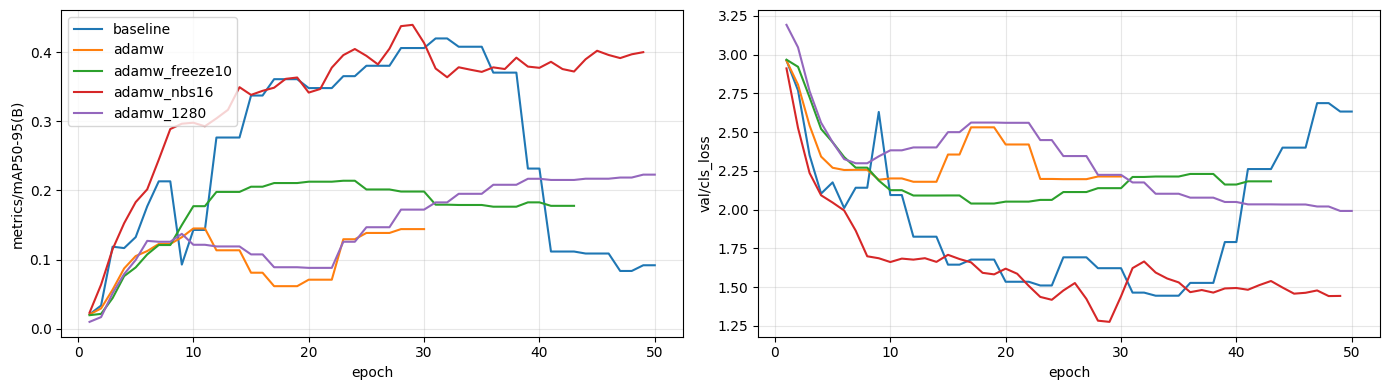

Выбор по val: adamw_nbs16 | models/real_adamw_nbs16/weights/best.pt


In [5]:
ranking = pd.DataFrame(runs).sort_values('val_map50_95', ascending=False)
display(ranking[['experiment', 'peak_epoch', 'val_precision', 'val_recall',
                 'val_map50', 'val_map50_95', 'val_count_mae', 'weights']].round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for run in runs:
    history = pd.read_csv(ROOT / run['run_dir'] / 'results.csv')
    history.columns = history.columns.str.strip()
    for ax, column in zip(axes, ['metrics/mAP50-95(B)', 'val/cls_loss']):
        ax.plot(history['epoch'], history[column], label=run['experiment'])
        ax.set(xlabel='epoch', ylabel=column)
        ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()

selected = ranking.iloc[0]
print('Выбор по val:', selected['experiment'], '|', selected['weights'])


## 5. Предсказания на val

Рамки выбранной модели и число частиц на каждом кадре.


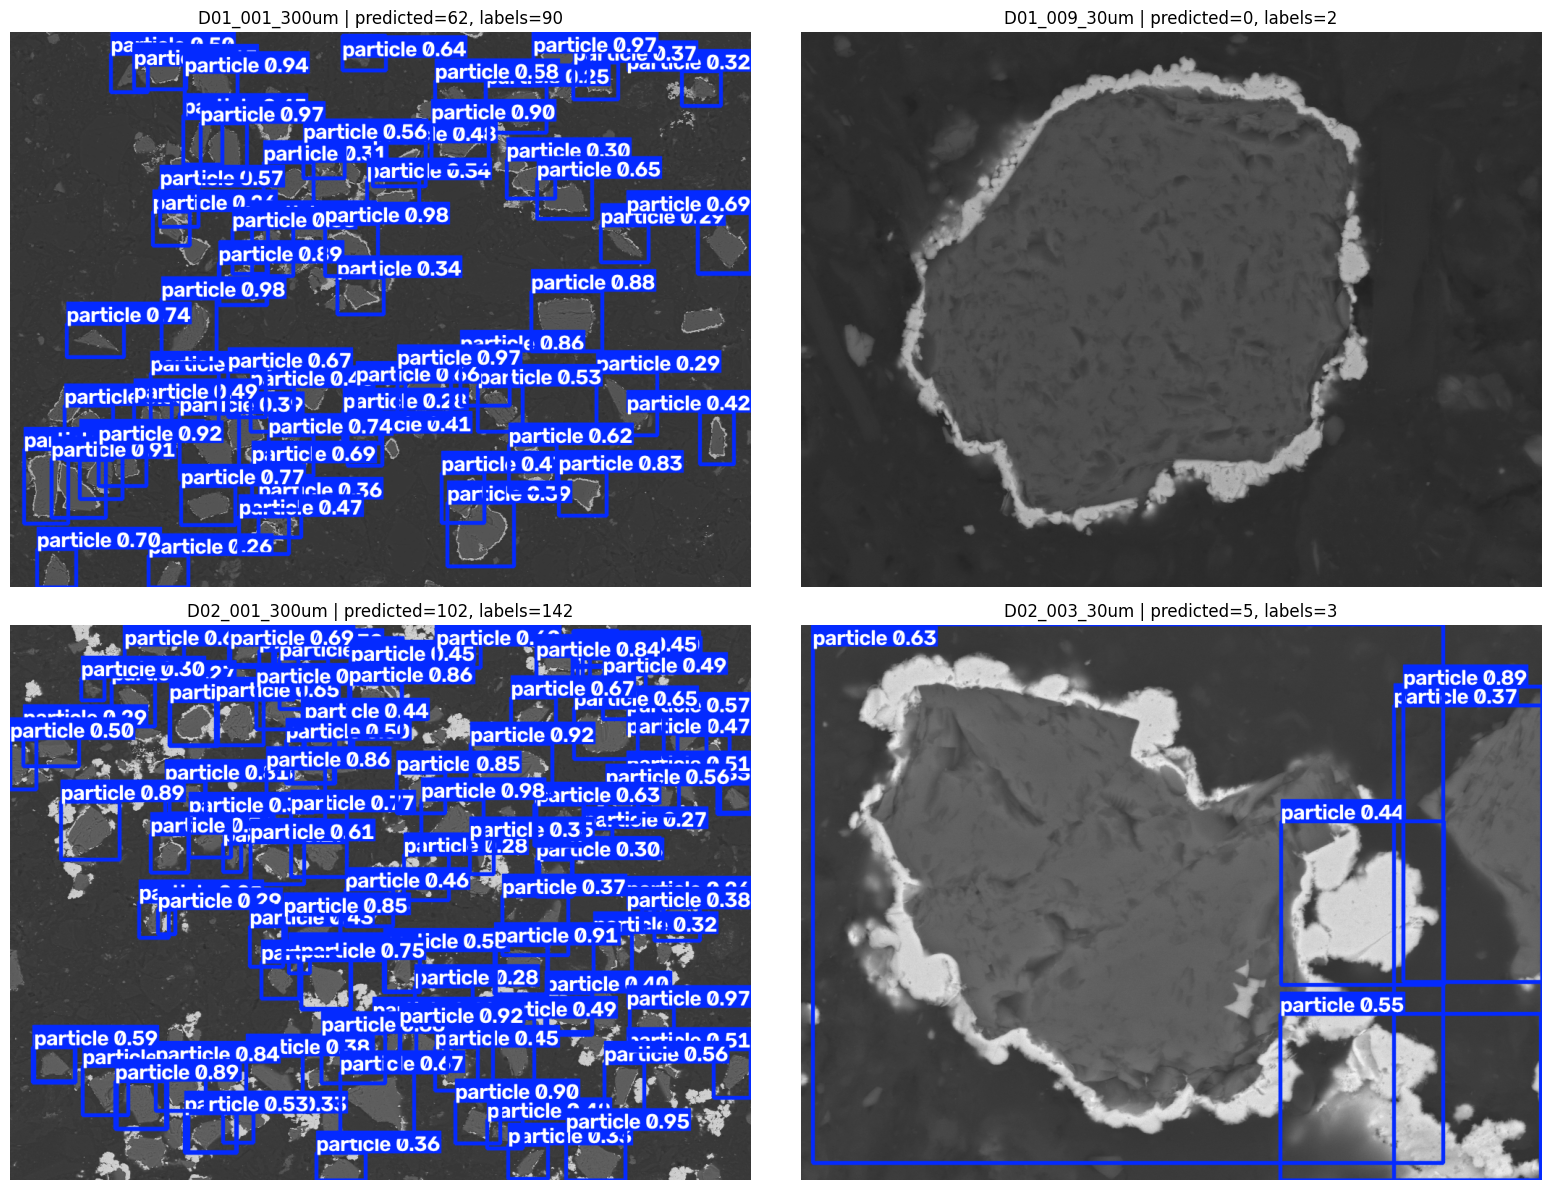

In [6]:
detector = YOLO(str(ROOT / selected['weights']), task='detect')
preview = [p for p in plans if p['split'] == 'val']
fig, axes = plt.subplots(math.ceil(len(preview) / 2), 2, figsize=(16, 6 * math.ceil(len(preview) / 2)), squeeze=False)
for ax, plan in zip(axes.flat, preview):
    result = detector.predict(
        source=str(plan['image']), imgsz=EVAL_IMAGE_SIZE, conf=CONFIDENCE,
        iou=0.7, max_det=MAX_DETECTIONS, device=DEVICE, rect=True, augment=False,
        half=False, save=False, save_txt=False, verbose=False,
    )[0]
    ax.imshow(result.plot()[:, :, ::-1])
    ax.set_title(f"{plan['image'].stem} | predicted={len(result.boxes)}, labels={plan['objects']}")
    ax.axis('off')
for ax in list(axes.flat)[len(preview):]:
    ax.axis('off')
plt.tight_layout()
plt.show()
del detector
gc.collect()
torch.cuda.empty_cache()


## 6. Test

Финальная оценка всех заранее заданных вариантов. Подбор параметров выполняется по val.
Помимо общих метрик выводится ошибка подсчёта по кадрам; test содержит три изображения.


In [7]:
test_counts = []
for row in runs:
    detector = YOLO(str(ROOT / row['weights']), task='detect')
    values, counts = evaluate(detector, ROOT / row['run_dir'], 'test')
    row.update(values)
    save_comparison(row)
    test_counts.append(counts.assign(experiment=row['experiment']))
    del detector
    gc.collect()
    torch.cuda.empty_cache()

display(pd.DataFrame(runs)[['experiment', 'test_precision', 'test_recall',
                           'test_map50', 'test_map50_95', 'test_count_mae']].round(4))
display(pd.concat(test_counts, ignore_index=True)[['experiment', 'image', 'labels', 'predicted', 'absolute_error']])


Ultralytics 8.4.24  Python-3.10.6 torch-2.9.1+cu128 CUDA:0 (NVIDIA GeForce RTX 5070, 12227MiB)
YOLO26s summary (fused): 122 layers, 9,465,567 parameters, 0 gradients, 20.5 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 689.7188.3 MB/s, size: 1557.7 KB)
val: Scanning C:\games\!!!studyMaga\2026\PP_Particles\PP_Particles\data_real\labels\test... 3 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3/3 750.0it/s 0.0s
val: New cache created: C:\games\!!!studyMaga\2026\PP_Particles\PP_Particles\data_real\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 3.3it/s 0.3s
                   all          3        109      0.534      0.525      0.562      0.341
Speed: 1.2ms preprocess, 46.6ms inference, 0.0ms loss, 0.2ms postprocess per image
Ultralytics 8.4.24  Python-3.10.6 torch-2.9.1+cu128 CUDA:0 (NVIDIA GeForce RTX 5070, 12227MiB)
YOLO26s summary (fused): 122 layers, 9,465,567 parameters, 0 gradients, 20.5 

,experiment,test_precision,test_recall,test_map50,test_map50_95,test_count_mae
0,baseline,0.5338,0.5253,0.5619,0.3413,1.6667
1,adamw,0.2932,0.2397,0.2338,0.0861,33.6667
2,adamw_freeze10,0.3450,0.4128,0.2667,0.1484,28.0000
3,adamw_nbs16,0.6753,0.4954,0.5860,0.2929,15.0000
4,adamw_1280,0.2941,0.2202,0.1769,0.0834,33.3333


,experiment,image,labels,predicted,absolute_error
0,baseline,D05_001_400um,101,103,2
1,baseline,D05_003_40um,5,3,2
2,baseline,D05_011_10um,3,2,1
3,adamw,D05_001_400um,101,7,94
4,adamw,D05_003_40um,5,1,4
5,adamw,D05_011_10um,3,0,3
6,adamw_freeze10,D05_001_400um,101,19,82
7,adamw_freeze10,D05_003_40um,5,5,0
8,adamw_freeze10,D05_011_10um,3,1,2
9,adamw_nbs16,D05_001_400um,101,61,40


## 7. Сравнение датасетов

Общая таблица находится в `models/comparison.csv`. После выполнения обоих ноутбуков здесь будут обе серии.
Для каждой пары набор/вариант выводится последний запуск с теми же seed, лимитом эпох и настройками оценки.


In [8]:
comparison = pd.read_csv(COMPARISON)
comparable = comparison.loc[
    (comparison['seed'] == SEED) & (comparison['eval_imgsz'] == EVAL_IMAGE_SIZE)
    & (comparison['count_conf'] == CONFIDENCE) & (comparison['max_det'] == MAX_DETECTIONS)
    & (comparison['batch'] == BATCH_SIZE) & (comparison['epochs_limit'] == EPOCHS)
    & (comparison['patience'] == PATIENCE)
]
latest = comparable.drop_duplicates(['dataset', 'experiment'], keep='last')
display(latest.sort_values(['dataset', 'val_map50_95'], ascending=[True, False])[
    ['dataset', 'experiment', 'train_images', 'train_imgsz', 'val_map50_95',
     'test_map50_95', 'test_count_mae', 'weights']
].round(4))
display(latest.pivot(index='experiment', columns='dataset',
                     values=['val_map50_95', 'test_map50_95', 'test_count_mae']).round(4))


,dataset,experiment,train_images,train_imgsz,val_map50_95,test_map50_95,test_count_mae,weights
3,mixed,adamw_nbs16,36,1024,0.4735,NaN,NaN,models/mixed_adamw_nbs16/weights/best.pt
0,mixed,baseline,36,1024,0.4673,NaN,NaN,models/mixed_baseline/weights/best.pt
2,mixed,adamw_freeze10,36,1024,0.2186,NaN,NaN,models/mixed_adamw_freeze10/weights/best.pt
1,mixed,adamw,36,1024,0.1704,NaN,NaN,models/mixed_adamw/weights/best.pt
7,real,adamw_nbs16,24,1024,0.4393,0.2929,15.0000,models/real_adamw_nbs16/weights/best.pt
4,real,baseline,24,1024,0.4186,0.3413,1.6667,models/real_baseline/weights/best.pt
6,real,adamw_freeze10,24,1024,0.2131,0.1484,28.0000,models/real_adamw_freeze10/weights/best.pt
5,real,adamw,24,1024,0.1447,0.0861,33.6667,models/real_adamw/weights/best.pt
8,real,adamw_1280,24,1280,0.0509,0.0834,33.3333,models/real_adamw_1280/weights/best.pt


val_map50_95         test_map50_95         test_count_mae  \
dataset               mixed    real         mixed    real          mixed   
experiment                                                                 
adamw                0.1704  0.1447           NaN  0.0861            NaN   
adamw_1280              NaN  0.0509           NaN  0.0834            NaN   
adamw_freeze10       0.2186  0.2131           NaN  0.1484            NaN   
adamw_nbs16          0.4735  0.4393           NaN  0.2929            NaN   
baseline             0.4673  0.4186           NaN  0.3413            NaN   

                         
dataset            real  
experiment               
adamw           33.6667  
adamw_1280      33.3333  
adamw_freeze10  28.0000  
adamw_nbs16     15.0000  
baseline         1.6667